In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("emails.csv")
df = df.drop(columns=["Email No."], errors="ignore")
df = df.dropna()
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5172, 3001)


,the,to,ect,and,for,of,a,you,hou,in,on,is,this,enron,i,be,that,will,have,with,your,at,we,s,are,it,by,com,as,from,gas,or,not,me,deal,if,meter,hpl,please,re,...,bold,catch,performing,accepted,matters,batch,continuing,winning,symbol,offsystem,decisions,produced,ended,greatest,degree,solmonson,imbalances,fall,fear,hate,fight,reallocated,debt,reform,australia,plain,prompt,remains,ifhsc,enhancements,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,0,0,1,0,0,0,2,0,0,0,0,1,0,0,2,0,0,0,0,0,0,0,0,3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,8,13,24,6,6,2,102,1,27,18,21,13,0,1,61,4,2,0,0,2,0,12,9,95,4,3,3,3,12,3,1,21,1,12,0,1,0,0,2,15,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,0,0,1,0,0,0,8,0,0,4,2,0,0,0,8,0,0,0,0,0,0,2,0,2,0,0,0,0,2,0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,5,22,0,5,1,51,2,10,1,5,9,2,0,16,2,0,0,1,1,0,2,1,36,3,1,2,0,2,3,0,10,2,5,2,0,1,0,0,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,7,6,17,1,5,2,57,0,9,3,12,2,2,0,30,8,0,0,2,0,0,7,0,19,2,4,2,0,4,1,2,6,0,6,0,0,3,0,1,10,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [3]:
X = df.drop(columns=["Prediction"])
y = df["Prediction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 4137
Testing records: 1035


In [4]:
selector = SelectKBest(score_func=chi2, k=100)
X_train = selector.fit_transform(X_train, y_train)
X_test = selector.transform(X_test)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

In [6]:
print("KNN Accuracy :", round(accuracy_score(y_test, knn_pred), 4))
print("KNN Precision:", round(precision_score(y_test, knn_pred, zero_division=0), 4))
print("KNN Recall   :", round(recall_score(y_test, knn_pred, zero_division=0), 4))
print("KNN F1 Score :", round(f1_score(y_test, knn_pred, zero_division=0), 4))

KNN Accuracy : 0.8783
KNN Precision: 0.7702
KNN Recall   : 0.8267
KNN F1 Score : 0.7974


In [7]:
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

In [8]:
print("SVM Accuracy :", round(accuracy_score(y_test, svm_pred), 4))
print("SVM Precision:", round(precision_score(y_test, svm_pred, zero_division=0), 4))
print("SVM Recall   :", round(recall_score(y_test, svm_pred, zero_division=0), 4))
print("SVM F1 Score :", round(f1_score(y_test, svm_pred, zero_division=0), 4))

SVM Accuracy : 0.914
SVM Precision: 0.8576
SVM Recall   : 0.8433
SVM F1 Score : 0.8504


In [9]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [accuracy_score(y_test, knn_pred), accuracy_score(y_test, svm_pred)],
    "Precision": [precision_score(y_test, knn_pred, zero_division=0), precision_score(y_test, svm_pred, zero_division=0)],
    "Recall": [recall_score(y_test, knn_pred, zero_division=0), recall_score(y_test, svm_pred, zero_division=0)],
    "F1 Score": [f1_score(y_test, knn_pred, zero_division=0), f1_score(y_test, svm_pred, zero_division=0)]
})
results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.8783,0.7702,0.8267,0.7974
1,SVM,0.9140,0.8576,0.8433,0.8504


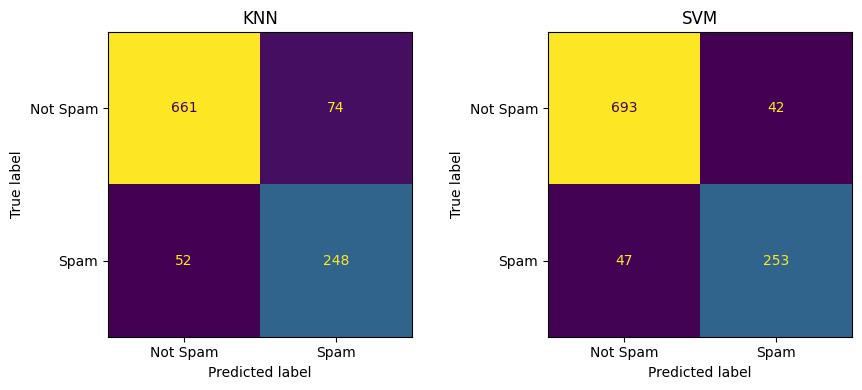

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, knn_pred), display_labels=["Not Spam", "Spam"]).plot(ax=axes[0], colorbar=False)
ConfusionMatrixDisplay(confusion_matrix(y_test, svm_pred), display_labels=["Not Spam", "Spam"]).plot(ax=axes[1], colorbar=False)
axes[0].set_title("KNN")
axes[1].set_title("SVM")
plt.tight_layout()
plt.show()